# 01. Limpeza e Preparação de Dados — Layoffs no Entretenimento Digital (2020–2026)

**Descrição:** Auditoria de qualidade, filtragem do recorte setorial (`Consumer` e `Media`), tratamento de inconsistências geográficas e duplicidades parciais, padronização de tipos e engenharia de atributos temporais e corporativos a partir da base bruta do *Layoffs.fyi*, preparando o dataset para carga no PostgreSQL e análise estatística.

<a id="top"></a>

## Índice

1. [Importação e Auditoria Inicial da Base Bruta](#secao-1)
2. [Classificação de Escopo Setorial](#secao-2)
3. [Auditoria de Duplicidades e Valores Ausentes](#secao-3)
   - [Explorando Duplicidade](#secao-31)
   - [Tratando Duplicidade](#secao-32)
   - [Explorando Valores Ausentes](#secao-33)
   - [Tratando Valores Ausentes](#secao-34)
4. [Padronização Geográfica e Categórica](#secao-4)
5. [Conversão de Tipos e Engenharia Temporal](#secao-5)
6. [Validação Final e Exportação](#secao-6)
<br>

---

<a id="secao-1"></a>

## 1. Importação e Auditoria Inicial da Base Bruta

In [17]:
# Configuração do Jupyter (Autoreload)
%load_ext autoreload
%autoreload 2

# Imports
import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

# Adiciona a raiz do projeto ao sys.path para conseguir importar a pasta src
sys.path.append(os.path.abspath('..'))

# Módulos auxiliares
from src.io.data_load import load_csv
from src.utils.data_quality import check_data_quality
from src.plots.visualizations import chart_data_quality

# Configurações de exibição do Pandas e estética dos gráficos
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['figure.dpi'] = 150

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
df_raw = load_csv("layoffs.csv")

In [19]:
df = df_raw.copy()

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4675 entries, 0 to 4674
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              4675 non-null   str    
 1   location             4674 non-null   str    
 2   total_laid_off       3048 non-null   float64
 3   date                 4675 non-null   str    
 4   percentage_laid_off  2917 non-null   float64
 5   industry             4673 non-null   str    
 6   source               4672 non-null   str    
 7   stage                4667 non-null   str    
 8   funds_raised         4119 non-null   float64
 9   country              4673 non-null   str    
 10  date_added           4675 non-null   str    
dtypes: float64(3), str(8)
memory usage: 401.9 KB


In [21]:
df_raw.head(10)

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Qualcomm,"Bengaluru, Non-U.S.",1500.00,11/11/2026,NaN,Hardware,https://timesofindia.indiatimes.com/business/india-business/qualcomm-layoffs-1500-employees-in-i...,Post-IPO,NaN,India,11/14/2026
1,Innoviz,"Tel Aviv, Non-U.S.",80.00,11/11/2026,0.20,Transportation,https://www.calcalistech.com/ctechnews/article/j23ch7kvd,Post-IPO,547.00,Israel,11/14/2026
2,Polymarket,New York City,NaN,11/11/2026,NaN,Finance,https://www.reuters.com/business/polymarket-cuts-jobs-contracts-prediction-market-competition-he...,Series E,2300.00,United States,11/14/2026
3,Val Town,New York City,NaN,11/10/2026,1.00,Product,https://blog.val.town/winding-down,Seed,7.00,United States,11/14/2026
4,Coursera,SF Bay Area,NaN,11/9/2026,0.10,Education,https://ca.investing.com/news/stock-market-news/faa-orders-nationwide-ground-stop-citing-extraor...,Acquired,458.00,United States,11/14/2026
5,Abridge,SF Bay Area,NaN,11/6/2026,NaN,Healthcare,https://www.modernhealthcare.com/health-tech/mh-abridge-layoffs-realignment-ai/,Series E,757.00,United States,11/7/2026
6,ServiceNow,SF Bay Area,NaN,11/6/2026,NaN,Support,https://www.calcalistech.com/ctechnews/article/s1t03axtg,Post-IPO,84.00,United States,11/10/2026
7,Bria,"Tel Aviv, Non-U.S.",20.00,11/5/2026,0.33,AI,https://www.calcalistech.com/ctechnews/article/5nu7gxmim,Series B,66.00,Israel,11/7/2026
8,Heidi Health,"Melbourne, Non-U.S.",108.00,11/4/2026,0.18,Healthcare,https://www.smh.com.au/technology/ai-start-up-heidi-cuts-jobs-weeks-after-raising-475-million-20...,Series C,432.00,Australia,11/7/2026
9,Block,SF Bay Area,NaN,11/4/2026,NaN,Finance,https://www.businessinsider.com/jack-dorsey-block-layoffs-second-round-job-cuts-cash-app-2026-11,Post-IPO,150.00,United States,11/7/2026


In [22]:
df.describe()

,total_laid_off,percentage_laid_off,funds_raised
count,3048.00,2917.00,4119.00
mean,310.84,0.30,968.05
std,1107.05,0.31,5574.12
min,3.00,0.00,0.70
25%,40.00,0.10,56.00
50%,90.00,0.17,177.00
75%,200.00,0.33,489.00
max,22000.00,1.00,121900.00


In [23]:
for col in df.columns:
    print(f"\nColuna: {col}")
    print(df[col].value_counts(dropna=False).head(10))


Coluna: company
company
Amazon        26
Google        19
Microsoft     18
Salesforce    15
Intel         13
Oracle        12
Rivian        12
Meta          12
Expedia       11
TikTok        10
Name: count, dtype: int64

Coluna: location
location
SF Bay Area            1160
New York City           460
Seattle                 207
Bengaluru, Non-U.S.     201
Boston                  197
Tel Aviv, Non-U.S.      179
Los Angeles             172
London, Non-U.S.        143
Berlin, Non-U.S.        100
Toronto, Non-U.S.        83
Name: count, dtype: int64

Coluna: total_laid_off
total_laid_off
NaN       1627
100.00     191
30.00      117
200.00     116
40.00      108
50.00       98
60.00       86
80.00       79
150.00      77
20.00       72
Name: count, dtype: int64

Coluna: date
date
4/2/2020      27
4/3/2020      25
1/18/2023     24
3/27/2020     23
4/8/2020      21
4/1/2020      21
11/15/2022    20
2/1/2023      19
1/10/2023     19
1/19/2023     18
Name: count, dtype: int64

Coluna: percent

### Resumo da Auditoria Inicial (Base Bruta)

* **Dimensões:** `4.675` registros e `11` colunas.
* **Estrutura e Tipagem:**
  * **Texto (`str` / 8 colunas):** `company`, `date` e `date_added` (4.675 válidos | 0 nulos), `location` (4.674 válidos | 1 nulo), `industry` e `country` (4.673 válidos | 2 nulos cada), `source` (4.672 válidos | 3 nulos) e `stage` (4.667 válidos | 8 nulos). *(Datas ainda como string, exigindo conversão para `datetime`.)*
  * **Numéricas (`float64` / 3 colunas):** `total_laid_off` (3.048 válidos | 1.627 nulos), `percentage_laid_off` (2.917 válidos | 1.758 nulos) e `funds_raised` (4.119 válidos | 556 nulos).
* **Diagnóstico Preliminar:**
  * Colunas críticas de identificação (`company`, `date`, `date_added`) possuem 100% de preenchimento, e os 2 nulos de `industry` serão auditados antes do filtro setorial.
  * Forte assimetria à direita nas variáveis quantitativas: em `total_laid_off`, a média (`310,84`) é mais de 3x superior à mediana (`90,00`), com amplitude de `3` a `22.000` demitidos.
  
<br>

---

<a id="secao-2"></a>

## 2. Classificação de Escopo Setorial

In [24]:
# Distribuição de setores na base bruta (incluindo nulos)
print("Distribuição de setores (Top 10 + Nulos):")
print(df['industry'].value_counts(dropna=False).head(20))

Distribuição de setores (Top 10 + Nulos):
industry
Finance           554
Retail            369
Healthcare        339
Consumer          322
Other             320
Transportation    278
Food              261
Marketing         226
Crypto            184
Security          171
Education         168
Real Estate       167
Media             165
Data              148
HR                117
Travel            115
Hardware           92
Infrastructure     80
Sales              80
Logistics          76
Name: count, dtype: int64


In [25]:
# Auditoria dos 2 registros com 'industry' nulo
print("\nRegistros com 'industry' nulo:")
display(df[df['industry'].isnull()][['company', 'location', 'total_laid_off', 'date', 'source']])


Registros com 'industry' nulo:


,company,location,total_laid_off,date,source
536,Eyeo,"Cologne, Non-U.S.",NaN,7/28/2025,https://www.adexchanger.com/privacy/eyeo-names-new-ceo-cuts-40-of-staff-and-refocuses-the-busine...
1604,Appsmith,SF Bay Area,35.00,9/22/2023,https://inc42.com/buzz/exclusive-insight-partners-backed-appsmith-lays-off-25-of-its-workforce/


In [26]:
# Remover apenas os 2 registros sem classificação setorial ('industry' nulo)
df_clean = df.dropna(subset=['industry']).copy().reset_index(drop=True)

In [27]:
# Criar flag de escopo setorial para permitir análise interna + benchmark de mercado
entertainment_sectors = ['Consumer', 'Media']
df_clean['sector_scope'] = np.where(
    df_clean['industry'].isin(entertainment_sectors),
    'Digital Entertainment',
    'Other Industries'
)


print(f"\nDimensões após filtro: {df_clean.shape[0]} linhas e {df_clean.shape[1]} colunas")
print(f"Representatividade na base bruta: {(len(df_clean) / len(df) * 100):.2f}%")
print("\nContagem por setor no recorte:")
print(df_clean['sector_scope'].value_counts())


Dimensões após filtro: 4673 linhas e 12 colunas
Representatividade na base bruta: 99.96%

Contagem por setor no recorte:
sector_scope
Other Industries         4186
Digital Entertainment     487
Name: count, dtype: int64


### Resumo da Classificação Setorial

* **Auditoria de Nulos em `industry`:** Os `2` registros sem classificação setorial na base bruta (*Eyeo* e *Appsmith*) foram auditados e removidos, mantendo **99,96%** da base original (`4.673` registros e `12` colunas, após a criação da coluna `sector_scope`).
* **Segmentação (`sector_scope`):**
  * **`Digital Entertainment` (`Consumer` + `Media`):** `487` eventos (**10,42%** da base válida), divididos em `322` em `Consumer` e `165` em `Media`.
  * **`Other Industries` (Demais setores de tecnologia):** `4.186` eventos (**89,58%** da base válida), mantidos como grupo de *benchmark* de mercado.

<br>

---

<a id="secao-3"></a>
## 3. Auditoria de Duplicidades e Valores Ausentes

In [28]:
# Checar Colunas do DataFrame Limpo
pd.DataFrame({'colunas': df_clean.columns})

,colunas
0,company
1,location
2,total_laid_off
3,date
4,percentage_laid_off
5,industry
6,source
7,stage
8,funds_raised
9,country


In [29]:
# Gerar relatório de qualidade dos dados
qa_report = check_data_quality(df_clean)
display(qa_report)

,Quantidade,Incidência (%)
percentage_laid_off (Nulos/NaN),1758,37.62
total_laid_off (Nulos/NaN),1626,34.80
funds_raised (Nulos/NaN),555,11.88
Duplicidade Parcial (Mesma Empresa + Data),23,0.49
stage (Nulos/NaN),8,0.17
source (Nulos/NaN),3,0.06
country (Nulos/NaN),2,0.04
location (Nulos/NaN),1,0.02
percentage_laid_off (Valores Zero),1,0.02


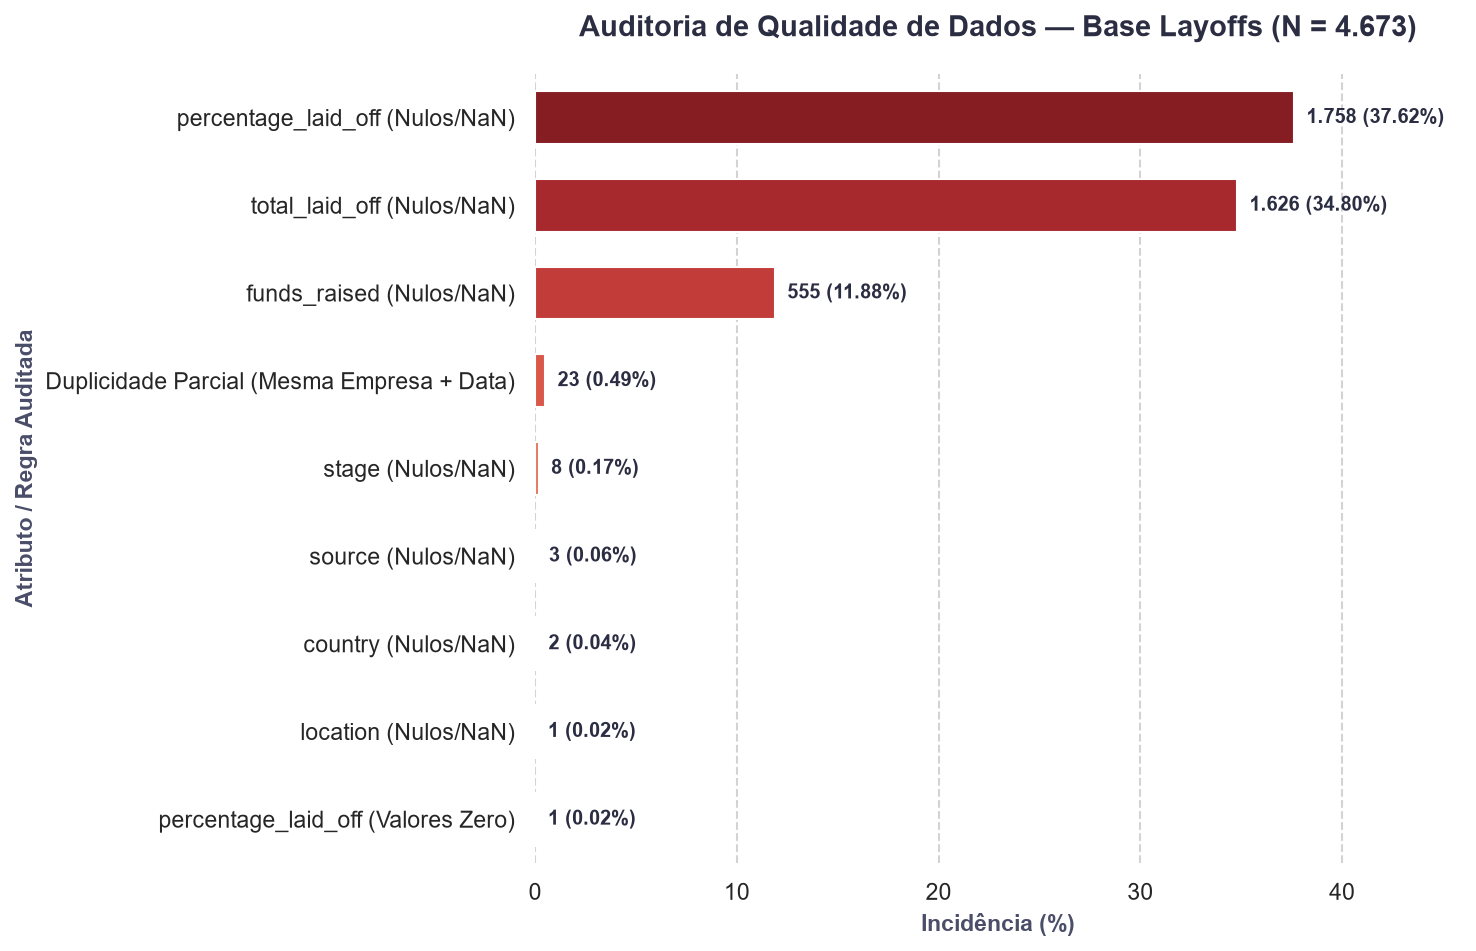

In [30]:
# Visualizar o relatório de qualidade dos dados
chart_data_quality(qa_report, nome_dataframe="Base Layoffs (N = 4.673)")

<a id="secao-31"></a>
### 3.1 Explorando Duplicidade

In [31]:
# Inspecionar as 23 duplicidades parciais (mesma empresa + mesma data)
dup_mask = df_clean.duplicated(subset=['company', 'date'], keep=False)
print(f"Total de linhas envolvidas em duplicidade parcial: {dup_mask.sum()}")
display(
    df_clean[dup_mask]
    .sort_values(['company', 'date'])
    [['company', 'location', 'total_laid_off', 'percentage_laid_off', 'date', 'industry', 'source']]
)

Total de linhas envolvidas em duplicidade parcial: 44


,company,location,total_laid_off,percentage_laid_off,date,industry,source
144,Amazon,Port St. Lucie,1110.00,NaN,7/22/2026,Retail,https://www.msn.com/en-us/money/companies/amazon-to-renovate-two-florida-warehouses-for-400m-cut...
146,Amazon,Seattle,NaN,NaN,7/22/2026,Retail,https://www.reuters.com/business/world-at-work/amazon-cuts-jobs-its-artificial-general-intellige...
3627,Anodot,"Tel Aviv, Non-U.S.",35.00,0.27,7/6/2022,Data,https://www.calcalistech.com/ctechnews/article/sypfe11ms5
3629,Anodot,"Tel Aviv, Non-U.S.",15.00,0.20,7/6/2022,Data,https://www.calcalistech.com/ctechnews/article/sjy5hbre3
3194,Beyond Meat,Los Angeles,200.00,0.19,10/14/2022,Food,https://www.cnbc.com/2022/10/14/beyond-meat-to-cut-19percent-of-its-workforce-as-sales-stock-str...
3195,Beyond Meat,Los Angeles,200.00,0.19,10/14/2022,Food,https://www.fooddive.com/news/beyond-meat-layoffs-cut-revenue-outlook/634141/
4490,Bustle Digital Group,New York City,24.00,0.08,4/3/2020,Media,https://digiday.com/media/bustle-digital-group-g-o-media-announce-layoffs-and-cost-saving-measures/
4491,Bustle Digital Group,New York City,19.00,NaN,4/3/2020,Media,https://www.adweek.com/media/bdg-input-mic-layoffs/
3736,Bybit,"Singapore, Non-U.S.",600.00,0.30,6/20/2022,Crypto,https://techcrunch.com/2022/06/20/bybit-crypto-exchange-joins-the-the-list-of-companies-cutting-...
3743,Bybit,"Singapore, Non-U.S.",NaN,NaN,6/20/2022,Crypto,https://twitter.com/WuBlockchain/status/1538807715861962752


<a id="secao-32"></a>
### 3.2. Tratando Duplicidade

<a id="secao-33"></a>
### 3.3. Explorando Valores Ausentes

<a id="secao-34"></a>
### 3.4. Tratando Valores Ausentes

<a id="secao-4"></a>
## 4. Padronização Geográfica e Categórica

<a id="secao-5"></a>
## 5. Conversão de Tipos e Engenharia Temporal

<a id="secao-6"></a>
## 6. Validação Final e Exportação